FATHER DNA: ATGCGATTACAGGCTAGCTAGGCGCGATTACATATAGCGCCCGGATCGATCGTATAGGCCGCGATTACAAAATGCGATCGGCGCTATAGCCGGATCGATTACAGCTAGCTAGGCGATTACATATAGCGCGGATCGATCGTAGGCCCGGATTACAAATGCGCTAGCTATAGGCGATTACAC
MOTHER DNA: ATGCGGGGATCGATCGCTAGCGCGATCGATATAGCGCAAATTTTATCGATCGTATAGGCCTATAGATTACAGGGGTGCGATCGGCGCTATAGCCAAATCGATCGAGCTAGCTAGGCGATCGATATAGCGCGGGGGATCGTAGGCCAAATCGATAAAATGCGCTAGCTATAGGCGATCGAC
CHILD DNA : GTGCGGGCATAGGCTGCTAGGGCGCGATTACATATAGCGCCCGGATCGATCGTATAGGCCTATAGATTACAATGCGATCGGCGCTGCTATAGCCAAATCGATCGAGCTAGCTAGGATTACATATAGCGCGGATCGATCGTAGGCCCGGATTACAAATGCGCTAGCCTATAGACGATCGAC

Father Fitness            : 33.20
Mother Fitness            : 20.80
Expected (Naive Avg Cross): 37.10
Achieved Child (Optimized): 47.80

Better than Father: True
Better than Mother: True
Better than Naive Expected Average: True

EXPECTED CHILD DNA (Naive 50/50 Crossover - No Optimization)
ATGCGATTACAGGCTAGCTAGGCGCGATTACATATAGCGCTTTTATCGATCGTATAGGCCTATAGATTACAGGGGTGCGATCGGCGCTATAGCCAAATCGATCGAGCTAGCTAGGCGATCATATAGCGCG

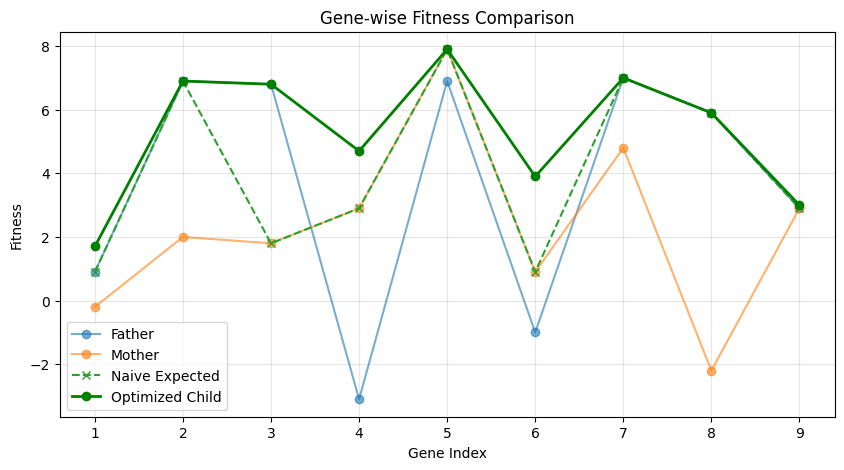

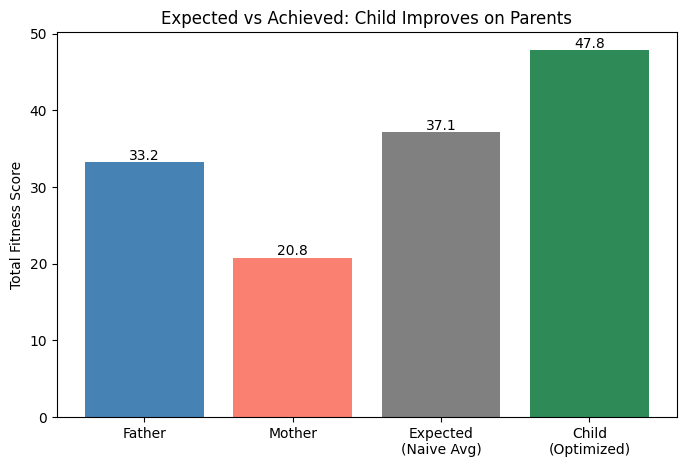


Files saved: child_dna.fasta, inheritance_log.csv, gene_fitness_comparison.png, total_fitness_comparison.png


In [ ]:
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

NUCLEOTIDES = ['A','T','G','C']
GENE_SIZE = 20
SUBBLOCK = 5
NUM_SUBBLOCKS = GENE_SIZE // SUBBLOCK
BENEFICIAL_MOTIFS = ['GATTACA','ATCG','CCGG','TATA','GCGC']
HARMFUL_MOTIFS = ['AAAA','TTTT','CGAT','GGGG']
MUTATION_RATE = 0.05

FATHER_DNA = "ATGCGATTACAGGCTAGCTAGGCGCGATTACATATAGCGCCCGGATCGATCGTATAGGCCGCGATTACAAAATGCGATCGGCGCTATAGCCGGATCGATTACAGCTAGCTAGGCGATTACATATAGCGCGGATCGATCGTAGGCCCGGATTACAAATGCGCTAGCTATAGGCGATTACACCGGATCGATCGTATAGCGC"
MOTHER_DNA = "ATGCGGGGATCGATCGCTAGCGCGATCGATATAGCGCAAATTTTATCGATCGTATAGGCCTATAGATTACAGGGGTGCGATCGGCGCTATAGCCAAATCGATCGAGCTAGCTAGGCGATCGATATAGCGCGGGGGATCGTAGGCCAAATCGATAAAATGCGCTAGCTATAGGCGATCGACCAAATCGATCGTATAGCGC"

def validate_dna(seq):
    seq = seq.strip().upper()
    if not seq or any(ch not in NUCLEOTIDES for ch in seq):
        raise ValueError(f"Invalid DNA sequence — only A/T/G/C allowed. Got: {seq[:50]}...")
    return seq

father_dna = validate_dna(FATHER_DNA)
mother_dna = validate_dna(MOTHER_DNA)

min_len = min(len(father_dna), len(mother_dna))
min_len -= min_len % GENE_SIZE
if min_len == 0:
    raise ValueError(f"Sequences too short — need at least {GENE_SIZE} bases each.")
father_dna, mother_dna = father_dna[:min_len], mother_dna[:min_len]
NUM_GENES = min_len // GENE_SIZE

def fitness_score(segment):
    score = 0
    for m in BENEFICIAL_MOTIFS:
        score += segment.count(m) * 2
    for m in HARMFUL_MOTIFS:
        score -= segment.count(m) * 3
    gc = (segment.count('G') + segment.count('C')) / len(segment)
    score += (1 - abs(gc - 0.5)) * 2
    return score

def build_markov_chain(seq, order=2):
    chain = {}
    for i in range(len(seq) - order):
        key = seq[i:i+order]
        nxt = seq[i+order]
        chain.setdefault(key, {}).setdefault(nxt, 0)
        chain[key][nxt] += 1
    for key in chain:
        total = sum(chain[key].values())
        for nxt in chain[key]:
            chain[key][nxt] /= total
    return chain

def markov_replacement(chain, context):
    if context in chain:
        options = list(chain[context].keys())
        probs = list(chain[context].values())
        return np.random.choice(options, p=probs)
    return random.choice(NUCLEOTIDES)

combined_chain = build_markov_chain(father_dna + mother_dna)

def recombine_gene(f_gene, m_gene):
    f_blocks = [f_gene[i*SUBBLOCK:(i+1)*SUBBLOCK] for i in range(NUM_SUBBLOCKS)]
    m_blocks = [m_gene[i*SUBBLOCK:(i+1)*SUBBLOCK] for i in range(NUM_SUBBLOCKS)]
    child_blocks = []
    for fb, mb in zip(f_blocks, m_blocks):
        f_fit, m_fit = fitness_score(fb), fitness_score(mb)
        probs = np.exp([f_fit, m_fit]) / np.sum(np.exp([f_fit, m_fit]))
        chosen = fb if np.random.choice(['f','m'], p=probs) == 'f' else mb
        child_blocks.append(chosen)
    child_gene = list(''.join(child_blocks))
    for i in range(len(child_gene)):
        if random.random() < MUTATION_RATE:
            context = ''.join(child_gene[i-2:i]) if i >= 2 else None
            if context and len(context) == 2:
                child_gene[i] = markov_replacement(combined_chain, context)
            else:
                child_gene[i] = random.choice(NUCLEOTIDES)
    return ''.join(child_gene)

def best_child_gene(f_gene, m_gene, attempts=6):
    candidates = [recombine_gene(f_gene, m_gene) for _ in range(attempts)]
    best = max(candidates, key=fitness_score)
    better_parent_gene = f_gene if fitness_score(f_gene) >= fitness_score(m_gene) else m_gene
    if fitness_score(best) < fitness_score(better_parent_gene):
        best = better_parent_gene
    return best

def naive_average_gene(f_gene, m_gene):
    return random.choice([f_gene, m_gene])

child_dna, naive_dna = '', ''
log = []
for g in range(NUM_GENES):
    s, e = g*GENE_SIZE, (g+1)*GENE_SIZE
    f_gene, m_gene = father_dna[s:e], mother_dna[s:e]
    n_gene = naive_average_gene(f_gene, m_gene)
    c_gene = best_child_gene(f_gene, m_gene)
    naive_dna += n_gene
    child_dna += c_gene
    log.append({'gene': g+1,'father_fit': fitness_score(f_gene),'mother_fit': fitness_score(m_gene),
                'naive_fit': fitness_score(n_gene),'child_fit': fitness_score(c_gene)})

log_df = pd.DataFrame(log)

father_fit = log_df['father_fit'].sum()
mother_fit = log_df['mother_fit'].sum()
naive_fit = log_df['naive_fit'].sum()
child_fit = log_df['child_fit'].sum()

print("FATHER DNA:", father_dna)
print("MOTHER DNA:", mother_dna)
print("CHILD DNA :", child_dna)
print()
print(f"Father Fitness            : {father_fit:.2f}")
print(f"Mother Fitness            : {mother_fit:.2f}")
print(f"Expected (Naive Avg Cross): {naive_fit:.2f}")
print(f"Achieved Child (Optimized): {child_fit:.2f}")
print()
print("Better than Father:", child_fit > father_fit)
print("Better than Mother:", child_fit > mother_fit)
print("Better than Naive Expected Average:", child_fit > naive_fit)

print()
print("="*80)
print("EXPECTED CHILD DNA (Naive 50/50 Crossover - No Optimization)")
print("="*80)
print(naive_dna)
print(f"Fitness Score: {naive_fit:.2f}")

print()
print("="*80)
print("BETTER CHILD DNA (Markov-Optimized Recombination)")
print("="*80)
print(child_dna)
print(f"Fitness Score: {child_fit:.2f}")

print()
print("="*80)
print("POSITION-WISE DIFFERENCE (Expected vs Better)")
print("="*80)
diff_markers = ''.join('|' if a != b else '.' for a, b in zip(naive_dna, child_dna))
print("Expected:", naive_dna)
print("Better  :", child_dna)
print("Diff    :", diff_markers)
print(f"\nTotal positions changed: {diff_markers.count('|')} / {len(diff_markers)}")
print(f"Fitness Improvement: +{child_fit - naive_fit:.2f} ({((child_fit-naive_fit)/max(abs(naive_fit),1))*100:.1f}%)")

plt.figure(figsize=(10,5))
plt.plot(log_df['gene'], log_df['father_fit'], label='Father', marker='o', alpha=0.6)
plt.plot(log_df['gene'], log_df['mother_fit'], label='Mother', marker='o', alpha=0.6)
plt.plot(log_df['gene'], log_df['naive_fit'], label='Naive Expected', marker='x', linestyle='--')
plt.plot(log_df['gene'], log_df['child_fit'], label='Optimized Child', marker='o', linewidth=2, color='green')
plt.xlabel('Gene Index'); plt.ylabel('Fitness'); plt.title('Gene-wise Fitness Comparison')
plt.legend(); plt.grid(alpha=0.3)
plt.savefig('gene_fitness_comparison.png', dpi=150); plt.show()

plt.figure(figsize=(8,5))
labels = ['Father','Mother','Expected\n(Naive Avg)','Child\n(Optimized)']
values = [father_fit, mother_fit, naive_fit, child_fit]
colors = ['steelblue','salmon','gray','seagreen']
bars = plt.bar(labels, values, color=colors)
plt.ylabel('Total Fitness Score'); plt.title('Expected vs Achieved: Child Improves on Parents')
for b,v in zip(bars, values):
    plt.text(b.get_x()+b.get_width()/2, v, f'{v:.1f}', ha='center', va='bottom')
plt.savefig('total_fitness_comparison.png', dpi=150); plt.show()

with open('child_dna.fasta','w') as f:
    f.write('>Father\n'+father_dna+'\n>Mother\n'+mother_dna+'\n>Naive_Expected\n'+naive_dna+'\n>Child_Optimized\n'+child_dna+'\n')

log_df.to_csv('inheritance_log.csv', index=False)
print("\nFiles saved: child_dna.fasta, inheritance_log.csv, gene_fitness_comparison.png, total_fitness_comparison.png")